# Separation of Variables, Residuals, and the Schrödinger Equation in Industry

**Colin Casey, 2026.** Companion to Knight Ch. 40 and to `diffraction_dispersion.ipynb`. Library: `dgs/schrodinger_separation_industry.py` (tests: `tests/test_schrodinger_separation_industry.py`).

## In plain words

1. **Separation of variables.** If the potential doesn't change with time, guess $\Psi(x,t)=X(x)\,T(t)$. The equation splits into a time half and a space half that must equal the same constant: the energy $E$. The time half always gives $e^{-iEt/\hbar}$. The space half is an eigenvalue problem, and the boundary conditions allow only certain energies. That is quantization.
2. **The residual.** To check any claimed solution, plug it back in and see what's left over: $r=i\hbar\,\partial_t\Psi-\hat H\Psi$. Exactly zero means it's a solution. On a computer grid, the residual should shrink like $\Delta x^2$; a wrong energy leaves a residual that never shrinks.
3. **Industry.** The same 1D separated problems run real products. Chips leak current by tunneling. Flash memory writes bits by tunneling. Superconducting qubits are a Schrödinger equation in a circuit variable, and ion qubits are harmonic oscillators. Drug and fuel chemistry rests on separating nuclei from electrons. Recent Nobel prizes (quantum dots and attosecond pulses in 2023, circuit tunneling in 2025) sit on the same equations.

| § | What | Industry / modern physics |
|---|---|---|
| 1 | Separation step (SymPy) | |
| 2 | Exact residuals: box, plane wave, QHO, 3D box, superposition, wrong-energy control | |
| 3 | Fig. 1: grid residual ∝ Δx² | numerical-methods check used everywhere |
| 4 | Fig. 2: gate-oxide tunneling, high-k | Intel, Texas Instruments, Applied Materials |
| 5 | Fig. 3: one triangular-barrier exponent for NAND flash and attosecond ionization | Micron, Western Digital · 2023 Physics Nobel |
| 6 | Fig. 4: transmon qubit bands | IBM, Alphabet · 2025 Physics Nobel |
| 7 | Trapped-ion ground state, Lamb-Dicke | Honeywell (Quantinuum) |
| 8 | Fig. 5: H₂ Morse vibrations (Born-Oppenheimer) | ExxonMobil, Pfizer, Merck (as users) |
| 9 | Quantum wells / dots | Intel, Broadcom · 2023 Chemistry Nobel |
| 10 | Summary table, references | |

Kernel: **py312**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import schrodinger_separation_industry as s

OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442',
          blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
r = s.sympy_separation()
S = r['symbols']

## 1. The separation step (SymPy)

Substitute $\Psi=X(x)T(t)$ into $i\hbar\,\partial_t\Psi = -\frac{\hbar^2}{2m}\partial_x^2\Psi + V(x)\Psi$ and divide by $XT$:

In [2]:
display(Math(sp.latex(r['lhs']) + r'\;=\;' + sp.latex(r['rhs']) + r'\;=\;E'))
display(Math(r'\text{time half: } T(t) = ' + sp.latex(r['T_sol'])))
print('Left side depends only on t, right side only on x. Equal for all x and t only if both equal one constant, E.')
print('The time half is the same for every potential; all the physics is in the space half (an eigenvalue problem).')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Left side depends only on t, right side only on x. Equal for all x and t only if both equal one constant, E.
The time half is the same for every potential; all the physics is in the space half (an eigenvalue problem).


## 2. Exact residuals $r = i\hbar\,\partial_t\Psi - \hat H\Psi$

Each separated solution is substituted back into the full time-dependent equation, and SymPy simplifies what's left. The last row is a **negative control**: the box state with its energy raised by 1%.

In [3]:
rows = [
    (r'\text{infinite well } \sqrt{2/L}\sin(n\pi x/L)\,e^{-iE_nt/\hbar}', r['box']),
    (r'\text{free plane wave } e^{i(kx-\hbar k^2t/2m)}', r['plane']),
    *[(rf'\text{{QHO }} n={j}:\ H_{j}(\xi)e^{{-\xi^2/2}}e^{{-i({j}+1/2)\omega t}}', q) for j, q in enumerate(r['qho'])],
    (r'\text{3D box } X(x)Y(y)Z(z)T(t)', r['box3']),
    (r'\text{superposition } \psi_1e^{-iE_1t/\hbar}+\psi_2e^{-iE_2t/\hbar}', r['superposition']),
    (r'\text{control: box with } E \to 1.01\,E_n', r['wrong_energy']),
]
for name, res in rows:
    display(Math(name + r'\quad\Rightarrow\quad r = ' + sp.latex(res)))
display(Math(r'E_n = ' + sp.latex(r['box_E']) + r',\qquad E_{n_1n_2n_3} = ' + sp.latex(r['box3_E'])))
display(Math(r'\psi(0)=\psi(L)=' + sp.latex(r['box_bc'][0]) + r',\qquad \omega_{21} = (E_2-E_1)/\hbar = ' + sp.latex(r['bohr_omega'])))
print('Every true solution leaves r = 0 exactly; the 1%-wrong energy leaves r proportional to the wavefunction itself.')
print('3D box: one separation constant per axis, and the energies add. The superposition also gives r = 0 (the equation is')
print('linear), but it does NOT factor into X(x)T(t): its density sloshes at the Bohr frequency omega_21.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Every true solution leaves r = 0 exactly; the 1%-wrong energy leaves r proportional to the wavefunction itself.
3D box: one separation constant per axis, and the energies add. The superposition also gives r = 0 (the equation is
linear), but it does NOT factor into X(x)T(t): its density sloshes at the Bohr frequency omega_21.


## 3. Figure 1: the grid residual shrinks like $\Delta x^2$

On a grid, $\hat H$ becomes the 3-point finite-difference matrix (ħ = m = L = 1). Applying it to the **exact** box state $\sin(\pi x)$ with the exact $E_1=\pi^2/2$ leaves a residual from discretization only, so it should fall like $\Delta x^2$. With the wrong energy the residual levels off at $0.01\,E_1$, however fine the grid.

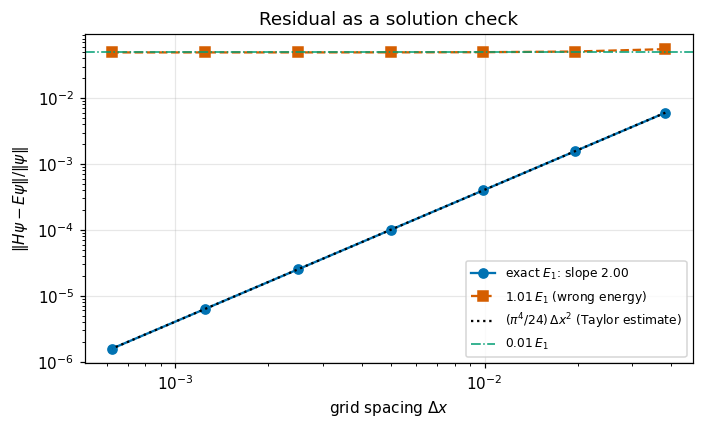

Figure 1. Log-log residual against grid spacing. Blue circles (solid) use the exact energy and fall with slope 2.00, on top of the dotted black Taylor estimate (pi^4/24) dx^2: the 3-point second derivative errs by psi''''dx^2/12. Red squares (dashed) use a 1% wrong energy and flatten onto the green dash-dot line at 0.01 E_1 = 0.0493. Refining the grid cannot rescue a wrong eigenvalue, which is why the residual is a reliable check.


In [4]:
good = s.box_residual_convergence(ns=(25, 50, 100, 200, 400, 800, 1600))
bad = s.box_residual_convergence(ns=(25, 50, 100, 200, 400, 800, 1600), energy_scale=1.01)
slope = np.polyfit(np.log(good[:, 0]), np.log(good[:, 1]), 1)[0]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(good[:, 0], good[:, 1], 'o-', color=OI['blue'], label=f'exact $E_1$: slope {slope:.2f}')
ax.loglog(bad[:, 0], bad[:, 1], 's--', color=OI['red'], label='$1.01\\,E_1$ (wrong energy)')
ax.loglog(good[:, 0], (np.pi**4/24)*good[:, 0]**2, ':', color=OI['black'], label='$(\\pi^4/24)\\,\\Delta x^2$ (Taylor estimate)')
ax.axhline(0.01*np.pi**2/2, color=OI['green'], ls='-.', lw=1, label='$0.01\\,E_1$')
ax.set(xlabel='grid spacing $\\Delta x$', ylabel='$\\|H\\psi-E\\psi\\|/\\|\\psi\\|$', title='Residual as a solution check'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'Figure 1. Log-log residual against grid spacing. Blue circles (solid) use the exact energy and fall with slope {slope:.2f}, '
      'on top of the dotted black Taylor estimate (pi^4/24) dx^2: the 3-point second derivative errs by psi\'\'\'\'dx^2/12. '
      'Red squares (dashed) use a 1% wrong energy and flatten onto the green dash-dot line at 0.01 E_1 = '
      f'{0.01*np.pi**2/2:.4f}. Refining the grid cannot rescue a wrong eigenvalue, which is why the residual is a reliable check.')

## 4. Figure 2: gate-oxide tunneling (Intel, Texas Instruments, Applied Materials)

A MOSFET gate sits on a thin SiO₂ layer: a **rectangular barrier** about 3.1 eV high for electrons (effective mass ≈ 0.5 mₑ). The exact transmission $T=[1+V_0^2\sinh^2(\kappa a)/4E(V_0-E)]^{-1}$ (from `dgs.tunneling`) falls as $e^{-2\kappa a}$. As oxides shrank toward 1 nm, gate leakage became a power problem. The industry fix (high-k HfO₂ around the 45 nm node) keeps the capacitance of a thin oxide while making the barrier physically thicker. The equivalent oxide thickness is $\text{EOT}=t_\text{phys}\,k_{\text{SiO}_2}/k$.

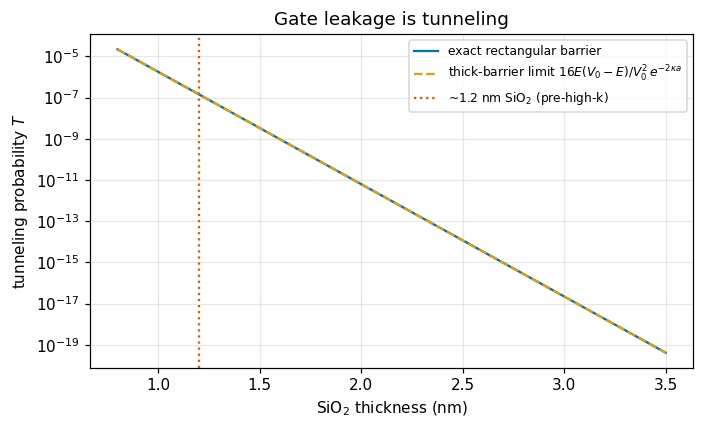

Figure 2. Semilog tunneling probability through SiO2 (barrier 3.1 eV, electron energy 0.1 eV, m* = 0.5 m_e) against thickness. Solid blue is exact; dashed orange is the thick-barrier exponential, which merges with it above ~1 nm. The dotted red line marks the ~1.2 nm oxides used before high-k.
kappa = 6.27e+09 1/m, decay length 1/(2 kappa) = 0.080 nm; each 0.1 nm thinner multiplies leakage by 3.5x.
High-k: 3.0 nm of HfO2 (k~25) has EOT = 0.47 nm; going from 0.47 nm to 3.0 nm of physical barrier cuts T by ~6.2e+13 (same SiO2 barrier assumed; real HfO2 has a lower barrier, so the true gain is smaller).


In [5]:
t = np.linspace(0.8, 3.5, 200)
T = s.gate_oxide_transmission(t)
kappa = np.sqrt(2*0.5*s.ME*3.0*s.QE)/s.HBAR
per_A = s.gate_oxide_transmission(1.0)/s.gate_oxide_transmission(1.1)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(t, T, '-', color=OI['blue'], label='exact rectangular barrier')
ax.semilogy(t, 16*0.1*3.0/3.1**2*np.exp(-2*kappa*t*1e-9), '--', color=OI['orange'], label='thick-barrier limit $16E(V_0-E)/V_0^2\\,e^{-2\\kappa a}$')
ax.axvline(1.2, color=OI['red'], ls=':', label='~1.2 nm SiO$_2$ (pre-high-k)')
ax.set(xlabel='SiO$_2$ thickness (nm)', ylabel='tunneling probability $T$', title='Gate leakage is tunneling'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
eot = s.equivalent_oxide_thickness(3.0, 25.0)
print('Figure 2. Semilog tunneling probability through SiO2 (barrier 3.1 eV, electron energy 0.1 eV, m* = 0.5 m_e) against thickness. '
      'Solid blue is exact; dashed orange is the thick-barrier exponential, which merges with it above ~1 nm. The dotted red line marks '
      'the ~1.2 nm oxides used before high-k.')
print(f'kappa = {kappa:.3g} 1/m, decay length 1/(2 kappa) = {1e9/(2*kappa):.3f} nm; each 0.1 nm thinner multiplies leakage by {per_A:.1f}x.')
print(f'High-k: 3.0 nm of HfO2 (k~25) has EOT = {eot:.2f} nm; going from 0.47 nm to 3.0 nm of physical barrier cuts T by '
      f'~{s.gate_oxide_transmission(0.47)/s.gate_oxide_transmission(3.0):.1e} (same SiO2 barrier assumed; real HfO2 has a lower barrier, so the true gain is smaller).')

## 5. Figure 3: one exponent for NAND flash and attosecond physics

A strong field $F$ tilts the barrier into a triangle, $V=\phi-eFx$. WKB gives
$$T\sim e^{-2\gamma},\qquad 2\gamma=\frac{4\sqrt{2m}\,\phi^{3/2}}{3\hbar eF}.$$

* **NAND flash (Micron, Western Digital):** Fowler-Nordheim tunneling through ~3.1 eV SiO₂ at ~10 MV/cm moves electrons onto the floating gate (or charge-trap layer). $B=6.83\times10^9\sqrt{m^*/m}\,\phi^{3/2}$ V/m.
* **Attosecond pulses (2023 Physics Nobel: Agostini, Krausz, L'Huillier):** a 800 nm laser at $10^{14}$ W/cm² tilts an argon atom's Coulomb barrier ($I_p$ = 15.76 eV). The electron tunnels out, is driven back, and emits high harmonics up to $I_p+3.17\,U_p$ (the three-step model). The Keldysh parameter $\gamma_K=\sqrt{I_p/2U_p}$ near or below 1 marks the tunneling regime.

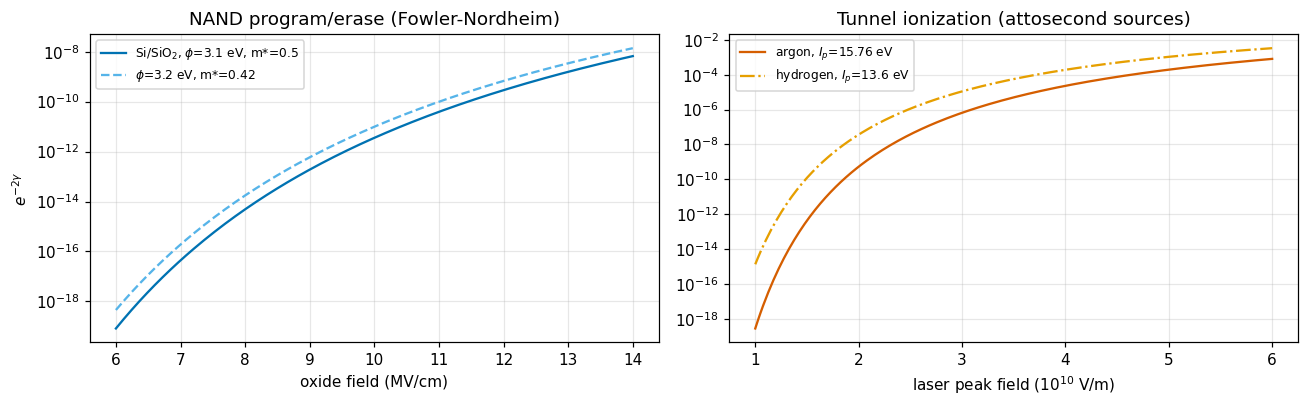

Figure 3. The same WKB exponent in two industries. Left: Fowler-Nordheim factor against oxide field for two common SiO2 parameter sets (solid blue, dashed sky blue); a few MV/cm changes it by orders of magnitude, which is why flash programming is controlled by voltage. Right: tunnel-ionization factor against laser field for argon (solid red) and hydrogen (dash-dot orange); the lower barrier ionizes more easily.
Flash: B = 264 MV/cm; 10 -> 12 MV/cm raises the factor 81x.
Laser 800 nm, 1e14 W/cm^2: F = 2.74e+10 V/m, U_p = 5.98 eV, Keldysh gamma (Ar) = 1.15, HHG cutoff = 34.7 eV (~36 nm, extreme UV).


In [6]:
F_flash = np.linspace(6e8, 1.4e9, 200)          # 6-14 MV/cm
F_laser = np.linspace(1e10, 6e10, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].semilogy(F_flash/1e8, np.exp(-s.triangular_barrier_exponent(3.1, F_flash, 0.5)), '-', color=OI['blue'], label='Si/SiO$_2$, $\\phi$=3.1 eV, m*=0.5')
ax[0].semilogy(F_flash/1e8, np.exp(-s.triangular_barrier_exponent(3.2, F_flash, 0.42)), '--', color=OI['sky'], label='$\\phi$=3.2 eV, m*=0.42')
ax[0].set(xlabel='oxide field (MV/cm)', ylabel='$e^{-2\\gamma}$', title='NAND program/erase (Fowler-Nordheim)'); ax[0].legend(fontsize=8)
ax[1].semilogy(F_laser/1e10, np.exp(-s.triangular_barrier_exponent(15.76, F_laser)), '-', color=OI['red'], label='argon, $I_p$=15.76 eV')
ax[1].semilogy(F_laser/1e10, np.exp(-s.triangular_barrier_exponent(13.6, F_laser)), '-.', color=OI['orange'], label='hydrogen, $I_p$=13.6 eV')
ax[1].set(xlabel='laser peak field ($10^{10}$ V/m)', title='Tunnel ionization (attosecond sources)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
F14 = s.laser_peak_field(1e14)
print('Figure 3. The same WKB exponent in two industries. Left: Fowler-Nordheim factor against oxide field for two common SiO2 '
      'parameter sets (solid blue, dashed sky blue); a few MV/cm changes it by orders of magnitude, which is why flash '
      'programming is controlled by voltage. Right: tunnel-ionization factor against laser field for argon (solid red) and '
      'hydrogen (dash-dot orange); the lower barrier ionizes more easily.')
print(f'Flash: B = {s.fowler_nordheim_B(3.1, 0.5)/1e8:.0f} MV/cm; 10 -> 12 MV/cm raises the factor '
      f'{np.exp(s.triangular_barrier_exponent(3.1, 1e9, 0.5)-s.triangular_barrier_exponent(3.1, 1.2e9, 0.5)):.0f}x.')
print(f'Laser 800 nm, 1e14 W/cm^2: F = {F14:.3g} V/m, U_p = {s.ponderomotive_energy_eV(1e14, 800e-9):.2f} eV, '
      f'Keldysh gamma (Ar) = {s.keldysh_gamma(15.76, 1e14, 800e-9):.2f}, HHG cutoff = {s.hhg_cutoff_eV(15.76, 1e14, 800e-9):.1f} eV '
      f'(~{1239.84/s.hhg_cutoff_eV(15.76, 1e14, 800e-9):.0f} nm, extreme UV).')

## 6. Figure 4: the transmon, a Schrödinger equation in a circuit (IBM, Alphabet; 2025 Physics Nobel)

A Josephson junction shunted by a capacitor has Hamiltonian
$$\hat H = 4E_C(\hat n-n_g)^2 - E_J\cos\hat\varphi,$$
where $\hat n$ is the number of Cooper pairs and $\varphi$ the superconducting phase. In the phase representation this is a 1D Schrödinger equation with a periodic **cosine potential**. Each well is nearly a harmonic oscillator, and tunneling between neighboring wells makes the levels depend on the stray offset charge $n_g$. In the charge basis $\cos\varphi$ just couples $n\to n\pm1$, so $H$ is tridiagonal. The 2025 Physics Nobel (Clarke, Devoret, Martinis) recognized the 1980s experiments showing that a circuit like this tunnels and has quantized levels. Transmons are the qubits in IBM's and Google's processors. A large $E_J/E_C$ suppresses the $n_g$ sensitivity exponentially (Koch et al.).

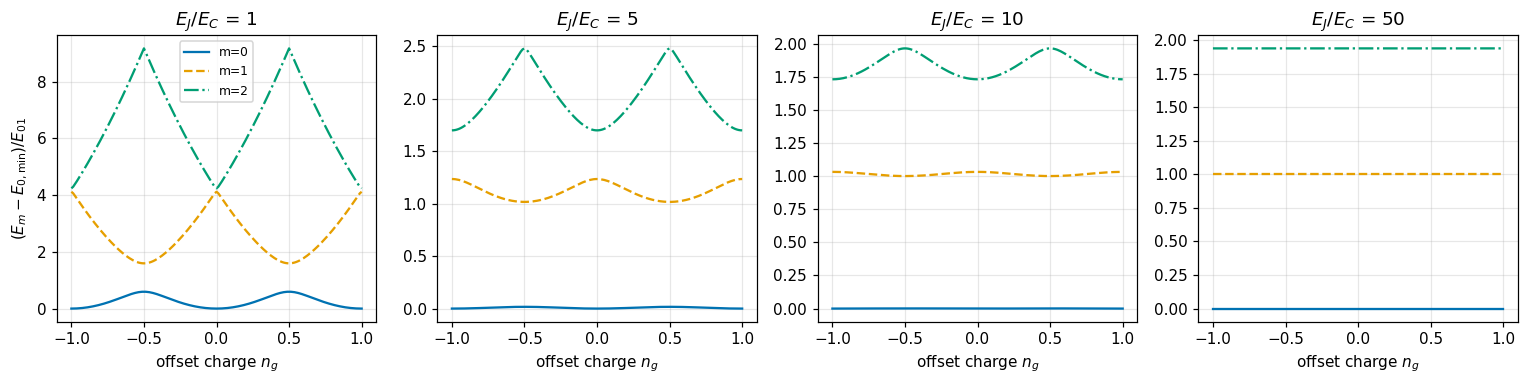

Figure 4. Lowest three transmon levels against offset charge n_g, for E_J/E_C = 1, 5, 10, 50 (left to right); level 0 solid blue, level 1 dashed orange, level 2 dash-dot green, energies in units of the 0-1 gap. At E_J/E_C = 1 (Cooper-pair box) the bands swing strongly with n_g, so charge noise dephases the qubit; by 50 they are flat lines (the transmon regime).
E_C/h = 0.25 GHz, E_J/E_C = 50: f01 = 4.735 GHz (asymptotic sqrt(8EJEC)-EC = 4.750), anharmonicity = -287 MHz (asymptotic -EC = -250 MHz).
  E_J/E_C=10: ground-state charge dispersion numeric 9.97e-03 E_C, Koch formula 1.11e-02 E_C
  E_J/E_C=20: ground-state charge dispersion numeric 4.27e-04 E_C, Koch formula 4.61e-04 E_C
  E_J/E_C=50: ground-state charge dispersion numeric 5.62e-07 E_C, Koch formula 5.88e-07 E_C


In [7]:
ng = np.linspace(-1, 1, 161)
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6), sharey=False)
styles = ['-', '--', '-.', ':']
for a, ratio in zip(ax, [1, 5, 10, 50]):
    lev = np.array([s.transmon_levels(ratio, 1.0, g, n_levels=3)[0] for g in ng])
    E01_mid = s.transmon_levels(ratio, 1.0, 0.5, n_levels=2)[0]
    norm = E01_mid[1] - E01_mid[0]
    for j, (c, ls) in enumerate(zip([OI['blue'], OI['orange'], OI['green']], styles)):
        a.plot(ng, (lev[:, j] - lev[:, 0].min())/norm, ls, color=c, label=f'm={j}')
    a.set(title=f'$E_J/E_C$ = {ratio}', xlabel='offset charge $n_g$')
ax[0].set_ylabel('$(E_m - E_{0,\\min})/E_{01}$'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
EC = 0.25
E, _, _ = s.transmon_levels(50*EC, EC)
f01, alpha = E[1]-E[0], (E[2]-E[1])-(E[1]-E[0])
f01_a, alpha_a = s.transmon_asymptotic(50*EC, EC)
print('Figure 4. Lowest three transmon levels against offset charge n_g, for E_J/E_C = 1, 5, 10, 50 (left to right); level 0 solid '
      'blue, level 1 dashed orange, level 2 dash-dot green, energies in units of the 0-1 gap. At E_J/E_C = 1 (Cooper-pair box) the '
      'bands swing strongly with n_g, so charge noise dephases the qubit; by 50 they are flat lines (the transmon regime).')
print(f'E_C/h = 0.25 GHz, E_J/E_C = 50: f01 = {f01:.3f} GHz (asymptotic sqrt(8EJEC)-EC = {f01_a:.3f}), '
      f'anharmonicity = {alpha*1e3:.0f} MHz (asymptotic -EC = {alpha_a*1e3:.0f} MHz).')
for ratio in (10, 20, 50):
    num = abs(s.transmon_levels(ratio, 1, 0.5)[0][0] - s.transmon_levels(ratio, 1, 0.0)[0][0])
    print(f'  E_J/E_C={ratio:2d}: ground-state charge dispersion numeric {num:.2e} E_C, Koch formula {s.transmon_charge_dispersion(ratio, 1):.2e} E_C')

## 7. Trapped-ion qubits: the harmonic oscillator (Honeywell / Quantinuum)

An ion in an RF Paul trap sits in a nearly harmonic well. Its motional ground state has size $x_0=\sqrt{\hbar/2m\omega}$. Laser gates couple the qubit to this motion with strength set by the **Lamb-Dicke parameter** $\eta=\Delta k\,x_0$. Gates work cleanly when $\eta\sqrt{2\bar n+1}\ll1$. Separating the Coulomb-coupled ion chain into normal modes is separation of variables again.

In [8]:
for name, mass in [('171Yb+', 170.936), ('137Ba+', 136.906), ('40Ca+', 39.963)]:
    x0 = s.ion_ground_state_size(mass, 1e6)
    print(f'{name:7s} at 1 MHz: x0 = {x0*1e9:5.2f} nm, eta (355 nm Raman, 90 deg) = {s.lamb_dicke(mass, 1e6, 355e-9):.3f}')
print('x0 is ~100x smaller than the laser wavelength, so the atom barely samples the light\'s phase: eta ~ 0.1, the Lamb-Dicke regime.')
print('Heavier ions or stiffer traps shrink x0 as 1/sqrt(m omega); the energy ladder E_n = (n+1/2) hbar omega is the one from Knight 40.8.')

171Yb+  at 1 MHz: x0 =  5.44 nm, eta (355 nm Raman, 90 deg) = 0.136
137Ba+  at 1 MHz: x0 =  6.08 nm, eta (355 nm Raman, 90 deg) = 0.152
40Ca+   at 1 MHz: x0 = 11.25 nm, eta (355 nm Raman, 90 deg) = 0.281
x0 is ~100x smaller than the laser wavelength, so the atom barely samples the light's phase: eta ~ 0.1, the Lamb-Dicke regime.
Heavier ions or stiffer traps shrink x0 as 1/sqrt(m omega); the energy ladder E_n = (n+1/2) hbar omega is the one from Knight 40.8.


## 8. Figure 5: quantum chemistry and Born-Oppenheimer (ExxonMobil, Pfizer, Merck as users)

Nuclei are ~1836× heavier than electrons. **Born-Oppenheimer** separates the molecular wavefunction, $\Psi\approx\chi(R)\,\psi_\text{el}(r;R)$: first solve for the electrons at fixed nuclear spacing $R$, which gives a potential curve; then solve a 1D Schrödinger equation for the nuclei in it. Catalysis, fuels and drug-binding chemistry, done with DFT and quantum-chemistry codes (and quantum-computing pilots), run this pipeline at scale. Here: the H₂ vibration in a Morse potential $V=D_e(1-e^{-ar})^2$, with closed form $G(v)=\omega_e(v+\tfrac12)-\omega_ex_e(v+\tfrac12)^2$, $\omega_ex_e=\omega_e^2/4D_e$.

 v   FD (cm^-1)  closed form  rel diff  eig residual
 0       2168.9       2168.9   2.2e-05       8.6e-12
 1       6316.9       6317.1   3.3e-05       3.4e-12
 2      10212.1      10212.6   4.8e-05       2.1e-12
 3      13854.4      13855.2   6.1e-05       1.3e-12
 4      17243.9      17245.1   7.1e-05       1.0e-12
 5      20380.6      20382.2   7.9e-05       9.9e-13
fundamental G(1)-G(0) = 4148 cm^-1 (measured H2: ~4161 cm^-1; Morse over-estimates anharmonicity slightly)


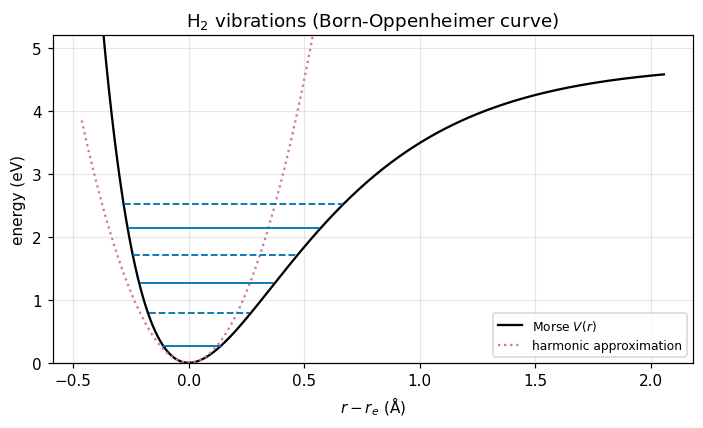

Figure 5. Morse potential for H2 (solid black) with the harmonic approximation (dotted purple) and the first six vibrational levels (blue, alternating solid/dashed), each drawn between its classical turning points. The levels crowd together toward the dissociation energy (4.75 eV), unlike the evenly spaced oscillator ladder, because the real well is softer on the right.


In [9]:
we, De, mu = 4401.0, 4.75, 1.00794/2
fd, res = s.morse_fd_levels_cm(6, we, De, mu)
cf = s.morse_levels_cm(np.arange(6), we, De)
print(f"{'v':>2s} {'FD (cm^-1)':>12s} {'closed form':>12s} {'rel diff':>9s} {'eig residual':>13s}")
for v in range(6):
    print(f'{v:2d} {fd[v]:12.1f} {cf[v]:12.1f} {abs(fd[v]/cf[v]-1):9.1e} {res[v]:13.1e}')
print(f'fundamental G(1)-G(0) = {cf[1]-cf[0]:.0f} cm^-1 (measured H2: ~4161 cm^-1; Morse over-estimates anharmonicity slightly)')
a_inv = 1/(2*np.pi*s.C_LIGHT*100*we*np.sqrt(mu*s.AMU/(2*De*s.QE)))
rr = np.linspace(-0.9, 4.0, 600)*a_inv
V = De*(1-np.exp(-rr/a_inv))**2
De_cm = De*s.QE/(s.H_PLANCK*s.C_LIGHT*100)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(rr*1e10, V, '-', color=OI['black'], label='Morse $V(r)$')
ax.plot(rr*1e10, 0.5*(2*np.pi*s.C_LIGHT*100*we)**2*mu*s.AMU*rr**2/s.QE, ':', color=OI['purple'], label='harmonic approximation')
for v in range(6):
    Ev = cf[v]/De_cm*De
    inside = rr[V < Ev]                                  # classically allowed region: turning point to turning point
    ax.hlines(Ev, inside[0]*1e10, inside[-1]*1e10, colors=OI['blue'], linestyles='--' if v % 2 else '-', lw=1.2)
ax.set(xlabel='$r-r_e$ (Å)', ylabel='energy (eV)', ylim=(0, 5.2), title='H$_2$ vibrations (Born-Oppenheimer curve)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 5. Morse potential for H2 (solid black) with the harmonic approximation (dotted purple) and the first six '
      'vibrational levels (blue, alternating solid/dashed), each drawn between its classical turning points. The levels crowd together toward the dissociation energy '
      '(4.75 eV), unlike the evenly spaced oscillator ladder, because the real well is softer on the right.')

## 9. Quantum wells and dots: the particle in a box (Intel, Broadcom; 2023 Chemistry Nobel)

Thin semiconductor layers confine electrons in one direction, so the levels follow $E_n=n^2h^2/8m^*L^2$ with an effective mass $m^*$. Quantum-well lasers and electro-absorption modulators in data-center optical transceivers use this. Confining all three directions gives a quantum dot (the 2023 Chemistry Nobel: Bawendi, Brus, Ekimov), where the 3D separated energies add and size tunes color.

In [10]:
for L in (5.0, 10.0, 15.0):
    E1, E2 = s.box_energy_eV([1, 2], L, 0.067)
    print(f'GaAs well (m*=0.067), L = {L:4.1f} nm: E1 = {E1*1e3:6.1f} meV, E2-E1 = {(E2-E1)*1e3:6.1f} meV -> '
          f'intersubband wavelength {1.23984/(E2-E1):5.2f} um')
Ed = s.box_energy_eV(1, 4.0, 0.13)*3
print(f'Cubic dot 4 nm, m*=0.13 (CdSe-like electron): ground confinement 3*E1 = {Ed:.2f} eV above the band edge (infinite-wall upper bound).')
print('Intersubband transitions at 5-15 um are the quantum-cascade-laser band used in gas sensing; interband lasers add confinement to the band gap.')

GaAs well (m*=0.067), L =  5.0 nm: E1 =  224.5 meV, E2-E1 =  673.5 meV -> intersubband wavelength  1.84 um
GaAs well (m*=0.067), L = 10.0 nm: E1 =   56.1 meV, E2-E1 =  168.4 meV -> intersubband wavelength  7.36 um
GaAs well (m*=0.067), L = 15.0 nm: E1 =   24.9 meV, E2-E1 =   74.8 meV -> intersubband wavelength 16.57 um
Cubic dot 4 nm, m*=0.13 (CdSe-like electron): ground confinement 3*E1 = 0.54 eV above the band edge (infinite-wall upper bound).
Intersubband transitions at 5-15 um are the quantum-cascade-laser band used in gas sensing; interband lasers add confinement to the band gap.


## 10. Summary

| Recent result | Schrödinger model | Section |
|---|---|---|
| 2025 Physics Nobel: macroscopic tunneling and quantized levels in a circuit | $4E_C n^2-E_J\cos\varphi$ | §6 |
| 2024 Google *Willow*: surface-code error correction below threshold | transmon qubits (see `docs/handoff_2026-10-10_tdgsa_qis_qec.md`) | §6 |
| 2023 Physics Nobel: attosecond pulses | triangular-barrier tunnel ionization | §5 |
| 2023 Chemistry Nobel: quantum dots | 3D particle in a box | §9 |
| Diffraction = dispersion = free particle | $\partial_p u=-\tfrac i2\partial_x^2u$ | `diffraction_dispersion.ipynb` |

In [11]:
print(f"{'companies':52s} {'physics':58s} model")
for row in s.INDUSTRY:
    print(f"{row['companies']:52s} {row['physics']:58s} {row['model']}")

companies                                            physics                                                    model
Intel, Texas Instruments, Applied Materials          direct tunneling through gate oxide                        rectangular barrier
Micron, Western Digital                              Fowler-Nordheim program/erase in NAND flash                triangular barrier (WKB)
IBM, Alphabet (Google Quantum AI)                    superconducting transmon qubits                            Schrodinger in phase: 4EC n^2 - EJ cos(phi)
Honeywell (majority owner of Quantinuum)             trapped-ion qubits, motional sidebands                     harmonic oscillator
ExxonMobil, Pfizer, Merck (users of quantum chemistry) molecular energies, spectra                                Born-Oppenheimer separation; Morse oscillator
Intel, Broadcom                                      quantum-well lasers / modulators in optical transceivers   particle in a box, effective mass
Corning            

## References

[1] J. Koch *et al.*, "Charge-insensitive qubit design derived from the Cooper pair box," *Phys. Rev. A*, vol. 76, no. 4, Art. no. 042319, 2007.
[2] J. M. Martinis, M. H. Devoret, and J. Clarke, "Energy-level quantization in the zero-voltage state of a current-biased Josephson junction," *Phys. Rev. Lett.*, vol. 55, no. 15, pp. 1543–1546, 1985.
[3] Google Quantum AI and collaborators, "Quantum error correction below the surface code threshold," *Nature*, vol. 638, pp. 920–926, 2025.
[4] D. J. Wineland *et al.*, "Experimental issues in coherent quantum-state manipulation of trapped atomic ions," *J. Res. Natl. Inst. Stand. Technol.*, vol. 103, no. 3, pp. 259–328, 1998.
[5] M. Lenzlinger and E. H. Snow, "Fowler-Nordheim tunneling into thermally grown SiO₂," *J. Appl. Phys.*, vol. 40, no. 1, pp. 278–283, 1969.
[6] J. Robertson, "High dielectric constant gate oxides for metal oxide Si transistors," *Rep. Prog. Phys.*, vol. 69, no. 2, pp. 327–396, 2006.
[7] L. V. Keldysh, "Ionization in the field of a strong electromagnetic wave," *Sov. Phys. JETP*, vol. 20, no. 5, pp. 1307–1314, 1965.
[8] P. B. Corkum, "Plasma perspective on strong field multiphoton ionization," *Phys. Rev. Lett.*, vol. 71, no. 13, pp. 1994–1997, 1993.
[9] P. M. Morse, "Diatomic molecules according to the wave mechanics. II. Vibrational levels," *Phys. Rev.*, vol. 34, no. 1, pp. 57–64, 1929.
[10] M. Born and R. Oppenheimer, "Zur Quantentheorie der Molekeln," *Ann. Phys.*, vol. 389, no. 20, pp. 457–484, 1927.
[11] R. D. Knight, *Physics for Scientists and Engineers with Modern Physics*, 5th ed. Hoboken, NJ, USA: Pearson, ch. 40.

**Limitations.**
- References are from memory; verify them before citing.
- Company lists say who uses the physics. They are not claims about any company's internal models, and Fortune 500 membership changes yearly (Google appears as Alphabet; Quantinuum is majority-owned by Honeywell).
- The device models are textbook simplifications. The rectangular gate-oxide barrier ignores image forces and band bending. The quantum well has infinite walls. The Morse fit uses $D_e$ = 4.75 eV, $\omega_e$ = 4401 cm⁻¹. The transmon omits readout and coupling circuitry.